In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from astropy.io import fits
from astropy.table import Table
import scipy.stats as stats

### [Sc/Mg] resampled delta chisquared data

Loading in the resampled data, alongside the original delta chisquare results

In [7]:
# Resampled data
resampled_dir = "/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg_mcmillan17/"
scmg_resampled_prodisk = pd.read_csv(resampled_dir + "scmg_prodisk_deltachisqrs_resample.csv")
scmg_resampled_gse = pd.read_csv(resampled_dir + "scmg_gse_deltachisqrs_resample.csv")

# resampled_addobsnoise = "/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg/tests/add_obs_noise/"
# scmg_resampled_addobsnoise_prodisk = pd.read_csv(resampled_addobsnoise + "scmg_prodisk_deltachisqrs_resample.csv")
# scmg_resampled_addobsnoise_gse = pd.read_csv(resampled_addobsnoise + "scmg_gse_deltachisqrs_resample.csv")

# resampled_binshift025 = "/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg/tests/bin_shift_025/"
# scmg_resampled_binshift025_prodisk = pd.read_csv(resampled_binshift025 + "scmg_prodisk_deltachisqrs_resample.csv")
# scmg_resampled_binshift025_gse = pd.read_csv(resampled_binshift025 + "scmg_gse_deltachisqrs_resample.csv")

# resampled_stopfehm350 = "/data/misfit/benlowe/xshooter/p115/chisqrs_resample/scmg/tests/stop_feh_m350/"
# scmg_resampled_stopfehm350_prodisk = pd.read_csv(resampled_stopfehm350 + "scmg_prodisk_deltachisqrs_resample.csv")
# scmg_resampled_stopfehm350_gse = pd.read_csv(resampled_stopfehm350 + "scmg_gse_deltachisqrs_resample.csv")


# Original chisquares
orig_dir = "/data/misfit/benlowe/xshooter/p115/results/abund_comparision/delta_chisqr_mcmillan17/"
scmg_orig_df = pd.read_csv(orig_dir + "scmg_abunds_mcmillan17_chisqr.csv")
scmg_orig_prodisk_deltachisqr = scmg_orig_df[scmg_orig_df["Region"] == "pro_disk"]['delta_chisqr'].values[0]
scmg_orig_gse_deltachisqr = scmg_orig_df[scmg_orig_df["Region"] == "gse"]['delta_chisqr'].values[0]

Determining the percentage of resamples above and below the original delta chisquare values

In [8]:
def calc_percentage(resampled_prodisk, resampled_gse, orig_prodisk_deltachisqr, orig_gse_deltachisqr):
    
    # For the prograde disk
    resampled_prodisk_above = resampled_prodisk[resampled_prodisk['delta_chisqr'] > orig_prodisk_deltachisqr]
    resampled_prodisk_below = resampled_prodisk[resampled_prodisk['delta_chisqr'] <= orig_prodisk_deltachisqr]
    resampled_prodisk_above_frac = len(resampled_prodisk_above) / len(resampled_prodisk)
    resampled_prodisk_below_frac = len(resampled_prodisk_below) / len(resampled_prodisk)

    pval_prodisk = np.sum(resampled_prodisk['delta_chisqr'] >= orig_prodisk_deltachisqr) / len(resampled_prodisk)
    sigma_prodisk = stats.norm.isf(pval_prodisk)

    median_prodisk = np.percentile(resampled_prodisk['delta_chisqr'], 50)
    lower_1sigma_prodisk = np.percentile(resampled_prodisk['delta_chisqr'], 16)
    upper_1sigma_prodisk = np.percentile(resampled_prodisk['delta_chisqr'], 84)

    print(f"Prodisk: {resampled_prodisk_above_frac:.2%} above, {resampled_prodisk_below_frac:.2%} below, p-value: {pval_prodisk:.4f} ({sigma_prodisk:.2f} sigma)")
    print(f"Prodisk: median={median_prodisk:.2f}, 1-sigma range=({lower_1sigma_prodisk:.2f}, {upper_1sigma_prodisk:.2f})")

    # For the GSE
    resampled_gse_above = resampled_gse[resampled_gse['delta_chisqr'] > orig_gse_deltachisqr]
    resampled_gse_below = resampled_gse[resampled_gse['delta_chisqr'] <= orig_gse_deltachisqr]
    resampled_gse_above_frac = len(resampled_gse_above) / len(resampled_gse)
    resampled_gse_below_frac = len(resampled_gse_below) / len(resampled_gse)

    pval_gse = np.sum(resampled_gse['delta_chisqr'] >= orig_gse_deltachisqr) / len(resampled_gse)
    sigma_gse = stats.norm.isf(pval_gse)

    median_gse = np.percentile(resampled_gse['delta_chisqr'], 50)
    lower_1sigma_gse = np.percentile(resampled_gse['delta_chisqr'], 16)
    upper_1sigma_gse = np.percentile(resampled_gse['delta_chisqr'], 84)

    print(f"GSE: {resampled_gse_above_frac:.2%} above, {resampled_gse_below_frac:.2%} below, p-value: {pval_gse:.4f} ({sigma_gse:.2f} sigma)")
    print()
    
    # Storing the results in a dictionary
    results = {
        "prodisk": {
            "above_frac": resampled_prodisk_above_frac,
            "below_frac": resampled_prodisk_below_frac,
            "p_value": pval_prodisk,
            "sigma": sigma_prodisk,
            "median": median_prodisk,
            "1sigma_range": (lower_1sigma_prodisk, upper_1sigma_prodisk)
        },
        "gse": {
            "above_frac": resampled_gse_above_frac,
            "below_frac": resampled_gse_below_frac,
            "p_value": pval_gse,
            "sigma": sigma_gse,
            "median": median_gse,
            "1sigma_range": (lower_1sigma_gse, upper_1sigma_gse)
        }
    }
    
    return results

In [9]:
resampled_res = calc_percentage(scmg_resampled_prodisk, scmg_resampled_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr)
# resampled_addobsnoise_res = calc_percentage(scmg_resampled_addobsnoise_prodisk, scmg_resampled_addobsnoise_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr)
# resampled_binshift025_res = calc_percentage(scmg_resampled_binshift025_prodisk, scmg_resampled_binshift025_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr)
# resampled_stopfehm350_res = calc_percentage(scmg_resampled_stopfehm350_prodisk, scmg_resampled_stopfehm350_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr)

Prodisk: 0.31% above, 99.69% below, p-value: 0.0031 (2.74 sigma)
Prodisk: median=1.10, 1-sigma range=(0.28, 3.17)
GSE: 17.14% above, 82.86% below, p-value: 0.1714 (0.95 sigma)



Making histogram of the resampled data

In [10]:
def plot_histogram(res_dict, resampled_prodisk, resampled_gse, orig_prodisk_deltachisqr, orig_gse_deltachisqr, savepath=None):
    
    # Unpacking the dictionary
    median_prodisk = res_dict['prodisk']['median']
    lower_1sigma_prodisk, upper_1sigma_prodisk = res_dict['prodisk']['1sigma_range']
    pval_prodisk = res_dict['prodisk']['p_value']
    sigma_prodisk = res_dict['prodisk']['sigma']
    resampled_prodisk_above_frac = res_dict['prodisk']['above_frac']
    resampled_prodisk_below_frac = res_dict['prodisk']['below_frac']
    
    median_gse = res_dict['gse']['median']
    lower_1sigma_gse, upper_1sigma_gse = res_dict['gse']['1sigma_range']
    pval_gse = res_dict['gse']['p_value']
    sigma_gse = res_dict['gse']['sigma']
    resampled_gse_above_frac = res_dict['gse']['above_frac']
    resampled_gse_below_frac = res_dict['gse']['below_frac']
    
    # Setting up the bins for the histogram
    bin_size = 0.5
    min_val = 0.0 
    # max_val = np.max(all_prodisk_deltachisqr_df['delta_chisqr'])
    max_val = np.max(pd.concat([resampled_prodisk['delta_chisqr'], resampled_gse['delta_chisqr']]))
    custom_bins = np.arange(min_val, max_val + bin_size, bin_size)

    # Plotting the histogram of the delta chi-square values
    fig, axs = plt.subplots(2, 1, figsize=[5,8], sharex=True)
    fig.subplots_adjust(hspace=0.0)

    fig.supylabel('Count')
    axs[1].set_xlabel('Delta Chi-Square ([Sc/Mg])')
    axs[1].set_xlim(0, 43)

    # Resampled prograde disk
    ax = axs[0]
    ax.hist(resampled_prodisk['delta_chisqr'], bins=custom_bins, color='lawngreen', edgecolor='black', log=True, linewidth=0.5)
    ax.axvline(x=orig_prodisk_deltachisqr, color='black', linestyle='-', linewidth=2, label=f'Delta chisqr = {orig_prodisk_deltachisqr:.2f}')
    ax.axvline(x=median_prodisk, color='red', linestyle='--', linewidth=2, label=f'μ = {median_prodisk:.2f} (+{upper_1sigma_prodisk - median_prodisk:.2f}/-{median_prodisk - lower_1sigma_prodisk:.2f})')
    ax.axvspan(lower_1sigma_prodisk, upper_1sigma_prodisk, color='red', alpha=0.15)

    ax.legend(fancybox=False, fontsize=10)
    ax.text(41.5, 36000, 'Prograde Disk', fontsize=12, fontweight='bold', horizontalalignment='right')
    ax.text(41.5, 18000, f'p-value = {pval_prodisk:.4f} ({sigma_prodisk:.2f}σ)', fontsize=10, horizontalalignment='right')
    ax.text(41.5, 6000, f'% above = {resampled_prodisk_above_frac:.2%}\n% below = {resampled_prodisk_below_frac:.2%}', fontsize=10, horizontalalignment='right')

    # Resampled GSE
    ax = axs[1]
    ax.hist(resampled_gse['delta_chisqr'], bins=custom_bins, color='cornflowerblue', edgecolor='black', log=True, linewidth=0.5)
    ax.axvline(x=orig_gse_deltachisqr, color='black', linestyle='-', linewidth=2, label=f'Delta chisqr = {orig_gse_deltachisqr:.2f}')
    ax.axvline(x=median_gse, color='red', linestyle='--', linewidth=2, label=f'μ = {median_gse:.2f} (+{upper_1sigma_gse - median_gse:.2f}/-{median_gse - lower_1sigma_gse:.2f})')
    ax.axvspan(lower_1sigma_gse, upper_1sigma_gse, color='red', alpha=0.15)

    ax.legend(fancybox=False, fontsize=10)
    ax.text(41.5, 36000, 'GSE', fontsize=12, fontweight='bold', horizontalalignment='right')
    ax.text(41.5, 18000, f'p-value = {pval_gse:.2f} ({sigma_gse:.2f}σ)', fontsize=10, horizontalalignment='right')
    ax.text(41.5, 6000, f'% above = {resampled_gse_above_frac:.2%}\n% below = {resampled_gse_below_frac:.2%}', fontsize=10, horizontalalignment='right')

    if savepath is not None:
        plt.savefig(savepath + "resampled_delta_chisqr.png", dpi=300, bbox_inches='tight', facecolor='white')
        plt.savefig(savepath + "resampled_delta_chisqr.pdf", dpi=300, bbox_inches='tight', facecolor='white')

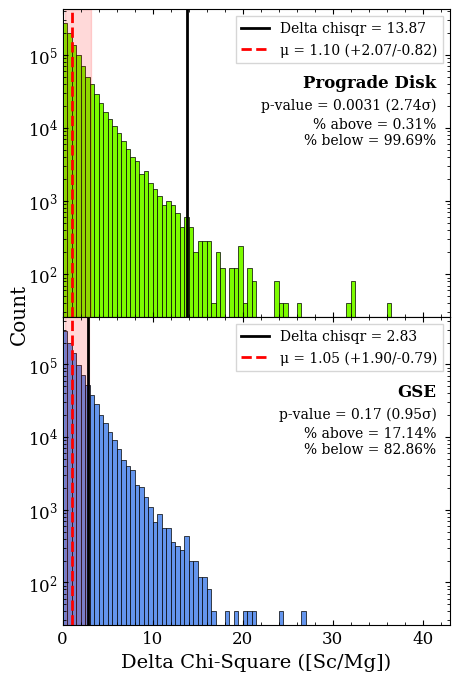

In [12]:
# Original resampled data
plot_histogram(resampled_res, scmg_resampled_prodisk, scmg_resampled_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr, savepath="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/resample_delta_chisqr_mcmillan17/")

# # Resampled data with added observational noise (±0.1 dex)
# plot_histogram(resampled_addobsnoise_res, scmg_resampled_addobsnoise_prodisk, scmg_resampled_addobsnoise_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr, savepath="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/resample_delta_chisqr/tests/add_obs_noise/")

# # Resampled data with 0.25 bin shift (went from -2.0, -2.5, -3.0 to -1.75, -2.25, -2.75 etc)
# plot_histogram(resampled_binshift025_res, scmg_resampled_binshift025_prodisk, scmg_resampled_binshift025_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr, savepath="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/resample_delta_chisqr/tests/bin_shift_025/")

# # Resampled data with FeH cutoff at -3.5 instead of -4.0 dex
# plot_histogram(resampled_stopfehm350_res, scmg_resampled_stopfehm350_prodisk, scmg_resampled_stopfehm350_gse, scmg_orig_prodisk_deltachisqr, scmg_orig_gse_deltachisqr, savepath="/data/misfit/benlowe/xshooter/p115/results/abund_comparision/resample_delta_chisqr/tests/stop_feh_m350/")